# (1) Example_MNIST_CNN_Train

Questo notebook contiene un esempio su come definire una Convolutional Neural Network (CNN) ed allenarla per eseguire Image Recognition sul dataset MNIST. La rete viene salvata alla fine del training.

## 1. Setup and Imports

Importiamo le librarie che ci serviranno

In [1]:
# Importazione delle librerie fondamentali per il progetto:
# numpy e matplotlib per array matematici e generazione grafici.

import numpy as np
import matplotlib.pyplot as plt

# torch e torchvision per la costruzione, gestione e trasformazione della rete neurale.
import torch
from torchvision import datasets, transforms

# tqdm per la generazione delle barre di avanzamento durante l'esecuzione.
from tqdm import tqdm

## 2. Data Preparation

Scarica il dataset MNIST per allenare la rete

In [2]:
# Indica il numero di campioni (immagini) elaborati parallelamente in una singola iterazione
# prima che la rete calcoli l'errore medio e aggiorni i propri pesi matematici.
# È un iperparametro fondamentale per bilanciare l'occupazione della memoria e la stabilità dell'apprendimento

# Inference batch size
batch_size = 64

# Download e pre-elaborazione del dataset MNIST (immagini 28x28 di numeri scritti a mano).
# Le immagini vengono convertite in Tensori e normalizzate statisticamente.

# Load the MNIST training set
# Istanzia il dataset MNIST puntando alla cartella corrente ("./"). 
# download=True: scarica il file se assente. train=True: seleziona le 60.000 immagini di addestramento.
mnist_data = datasets.MNIST("./", download=True, train=True,
                              # Pipeline di pre-elaborazione dell'immagine di input:
                              transform=transforms.Compose([
                                # 1. Converte l'immagine PIL in una matrice matematica (Tensore) con valori 0-1.
                                transforms.ToTensor(),
                                # 2. Centra i dati sottraendo la media globale (0.1307) e dividendo per la deviazione standard (0.3081) per ottimizzare la convergenza numerica.
                                transforms.Normalize((0.1307,), (0.3081,))  
                                ]),
                              # Pipeline di formattazione delle etichette (le risposte corrette):
                              target_transform=transforms.Compose([
                                lambda x:torch.tensor([x]), 
                                # Converte l'intero (es. "3") in un vettore logico "one-hot" di 10 elementi (es. [0,0,0,1,0,0,0,0,0,0]).
                                lambda x:torch.nn.functional.one_hot(x,10).float(),
                                lambda x:x.squeeze(),
                                ]))

# Load the MNIST test set
mnist_test = datasets.MNIST("./", download=True, train=False,
                              transform=transforms.Compose([
                                transforms.ToTensor(),
                                transforms.Normalize((0.1307,), (0.3081,))  
                                ]),
                              target_transform=transforms.Compose([
                                lambda x:torch.tensor([x]), 
                                lambda x:torch.nn.functional.one_hot(x,10).float(),
                                lambda x:x.squeeze(),
                                ]))

# Il dataset viene successivamente suddiviso: 80% per il training, 20% per la validazione 
# e un blocco separato (DataLoader) per il test finale (inferenza).

# Split dataset into training and validation and create data loaders
ds_train, ds_val = torch.utils.data.random_split(mnist_data, [0.8, 0.2])

# Crea gli iteratori per alimentare la rete. 'shuffle=True' rimescola casualmente le matrici 
# ad ogni epoca per impedire alla rete di memorizzare l'ordine sequenziale.
mnist_loader_train = torch.utils.data.DataLoader(ds_train, batch_size=batch_size, shuffle=True)
mnist_loader_val = torch.utils.data.DataLoader(ds_val, batch_size=batch_size, shuffle=False)

# Create test set loader
mnist_loader_test = torch.utils.data.DataLoader(mnist_test, batch_size=batch_size, shuffle=False)
N_test = len(mnist_loader_test.dataset)

## 3. Define the CNN Model

Definisci la tua rete neurale

In [3]:
# Definizione dell'architettura (topologia) della Rete Neurale Convoluzionale (CNN).
# Struttura ibrida composta da strati convoluzionali (Conv2d) per l'estrazione delle feature spaziali 
# e strati completamente connessi (Linear) per la classificazione probabilistica (output su 10 classi, da 0 a 9).

# Define the CNN topology
def mnist_cnn():
    # Inizializza un contenitore sequenziale: i dati attraverseranno i nodi esattamente nell'ordine elencato.
    return torch.nn.Sequential(
        # Primo strato convoluzionale (filtro spaziale): riceve 1 canale di input (immagine in scala di grigi),
        # genera 8 canali di output (feature maps), usando una finestra mobile (kernel) 3x3. 'stride=2' dimezza la risoluzione spaziale.
        torch.nn.Conv2d(1, 8, 3, padding='valid', stride=2),

        # Funzione di attivazione non lineare (Rectified Linear Unit). Azzera i segnali negativi e lascia inalterati i positivi.
        torch.nn.ReLU(),

        # Secondo strato convoluzionale: prende le 8 feature maps in ingresso ed estrae 16 nuovi canali, sempre dimezzando la risoluzione spaziale.
        torch.nn.Conv2d(8, 16, 3, padding='valid', stride=2),
        torch.nn.ReLU(),

        # Srotola le matrici multidimensionali risultanti in un singolo vettore monodimensionale, preparandole per il perceptrone classico.
        torch.nn.Flatten(),

        # Strato completamente connesso (moltiplicazione matriciale pura): mappa i 576 nodi in input su 16 neuroni nascosti.
        torch.nn.Linear(576, 16),
        torch.nn.ReLU(),

        # Strato di output finale: riduce i 16 neuroni nascosti ai 10 nodi di uscita, che corrispondono alle 10 cifre possibili (da 0 a 9).
        torch.nn.Linear(16, 10)
        )

# Definizione Rete con Dropout
def mnist_cnn_dropout():
    return torch.nn.Sequential(
        torch.nn.Conv2d(1, 8, 3, padding='valid', stride=2),
        torch.nn.ReLU(),
        torch.nn.Conv2d(8, 16, 3, padding='valid', stride=2),
        torch.nn.ReLU(),
        torch.nn.Flatten(),
        torch.nn.Dropout(p=0.3), # Spegne il 30% dei neuroni
        torch.nn.Linear(576, 16),
        torch.nn.ReLU(),
        torch.nn.Linear(16, 10)
    )

## 4. Training and Testing Functions

Definisci una funzione Wrapper che esponga un'interfaccia per lanciare training e testing sul modello.
Questa procedura non é "standard" Pythorch ma facilita l'utilizzo successivo del framework Cross-Sim per modellare l'implementazione via In-Memory Computing.

Per il training viene utilizzato l'ottimizzatore Adam con learning rate a $10^{-3}$.

In [4]:
# Creazione di una classe "Wrapper" personalizzata per la gestione del ciclo di vita della rete.
# Questa astrazione architetturale è propedeutica per la successiva integrazione con il framework Cross-Sim per l'In-Memory Computing.

# Wrapper for training the CNN
class SequentialWrapper():
    def __init__(self, net, loss, learning_rate=1e-3):
        self.net = net
        self.loss = loss
        self.learning_rate = learning_rate
        self.optimizer = torch.optim.Adam(self.net.parameters(), lr=self.learning_rate)

    # Definisce le funzioni di forward, calcolo dell'errore (CrossEntropyLoss) e ottimizzazione (Adam con lr=1e-3).
    def forward(self, x):
        return self.net(x)
    
    def training_step(self, batch):
        self.optimizer.zero_grad()
        pred = self.forward(batch[0])
        loss = self.loss(pred, batch[1])
        loss.backward()
        self.optimizer.step()
        return loss

    def validation_step(self, batch):
        pred = self.forward(batch[0])
        loss = self.loss(pred, batch[1])
        return loss
    
    def train_epoch(self, train_loader, val_loader):
        loss_train, loss_val = 0, 0
        for minibatch in iter(train_loader):
            loss_train += self.training_step(minibatch).detach()
        for minibatch in iter(val_loader):
            loss_val += self.validation_step(minibatch).detach()
        return loss_train/len(train_loader), loss_val/len(val_loader)
    
    def train(self, train_loader, val_loader, epochs):
        loss_train, loss_val = np.zeros(epochs), np.zeros(epochs)
        for e in tqdm(range(0, epochs)):
            lt, lv = self.train_epoch(train_loader, val_loader)
            loss_train[e] = lt
            loss_val[e] = lv
        return loss_train, loss_val

# Questa astrazione architetturale è propedeutica per la successiva integrazione con il framework Cross-Sim per l'In-Memory Computing.

# Create the wrapped PyTorch of the CNN model
mnist_cnn_pt = SequentialWrapper(mnist_cnn(), torch.nn.CrossEntropyLoss())

## 5. PyTorch Training

Allena (_training_) la rete per il numero di _epoche_ indicato.


In [5]:
# Esecuzione del ciclo di addestramento (Training) per un numero definito di epoche (N_epochs = 40).

# Number of training epochs
N_epochs = 40

# Prepariamo i due "cervelli"
mnist_cnn_pt = SequentialWrapper(mnist_cnn(), torch.nn.CrossEntropyLoss())
mnist_cnn_drop = SequentialWrapper(mnist_cnn_dropout(), torch.nn.CrossEntropyLoss())

print("--- INIZIO ADDESTRAMENTO RETE STANDARD ---")
loss_train_pt, loss_val_pt = mnist_cnn_pt.train(mnist_loader_train, mnist_loader_val, N_epochs)

print("\n--- INIZIO ADDESTRAMENTO RETE CON DROPOUT ---")
loss_train_drop, loss_val_drop = mnist_cnn_drop.train(mnist_loader_train, mnist_loader_val, N_epochs)


--- INIZIO ADDESTRAMENTO RETE STANDARD ---


100%|██████████| 40/40 [05:18<00:00,  7.97s/it]



--- INIZIO ADDESTRAMENTO RETE CON DROPOUT ---


100%|██████████| 40/40 [07:10<00:00, 10.75s/it]


Rappresenta poi la funzione costo (_loss_) per il subset di _training_ e di _testing_ per valutare eventuale overfitting.

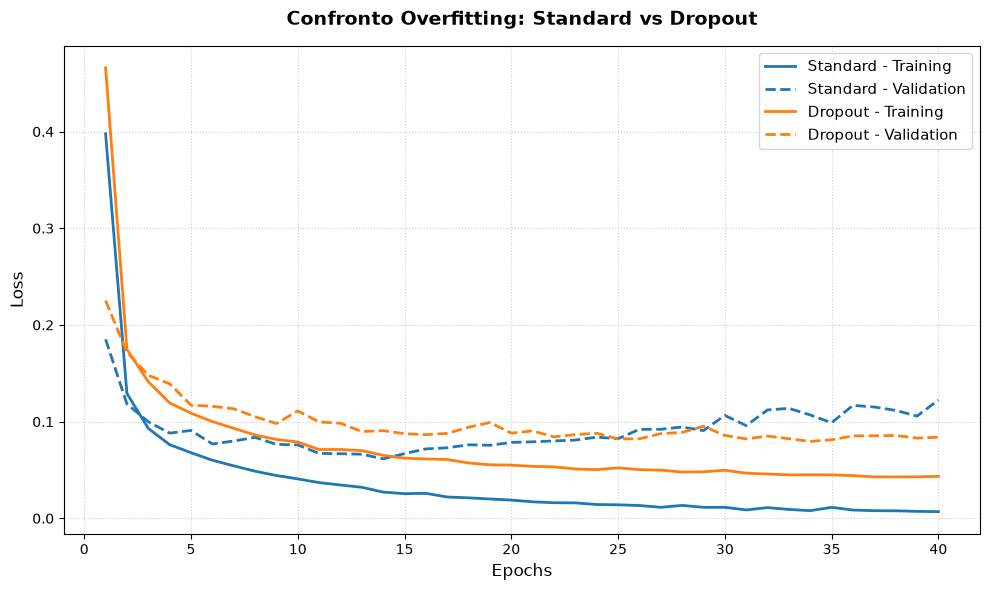

In [6]:
# Visualizzazione grafica delle curve di Training Loss e Validation Loss.
# Fondamentale per monitorare l'apprendimento ed escludere fenomeni di Overfitting 
# (quando la rete impara a memoria i dati di training peggiorando sui dati di validazione).

x_axis_epochs = np.arange(1, N_epochs + 1)

plt.figure(figsize=(10, 6))

# Traccia la Rete Standard (Blu)
plt.plot(x_axis_epochs, loss_train_pt, label='Standard - Training', color='#1f77b4', linewidth=2)
plt.plot(x_axis_epochs, loss_val_pt, label='Standard - Validation', color='#1f77b4', linewidth=2, linestyle='--')

# Traccia la Rete con Dropout (Arancione)
plt.plot(x_axis_epochs, loss_train_drop, label='Dropout - Training', color='#ff7f0e', linewidth=2)
plt.plot(x_axis_epochs, loss_val_drop, label='Dropout - Validation', color='#ff7f0e', linewidth=2, linestyle='--')

plt.title('Confronto Overfitting: Standard vs Dropout', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)

plt.tight_layout()
plt.savefig('confronto_overfitting.png', bbox_inches='tight', dpi=200)
plt.show()

## 6. PyTorch Inference

Una volta soddisfatto dal training, valuta l'accuratezza della rete su un subset completamente nuovo (_testing_).

In [7]:
# Fase di Inferenza (Testing) su dati mai visti durante l'addestramento.
# Valuta le prestazioni di entrambi i modelli nel dominio digitale "ideale".

# ATTENZIONE: Impostiamo le reti in modalità "valutazione" (eval). 
# Questo comando è vitale perché "spegne" il Dropout durante il test:
# la rete deve usare tutti i suoi neuroni quando viene messa alla prova.
mnist_cnn_pt.net.eval()
mnist_cnn_drop.net.eval()

y_pred_pt, y_pred_drop, y_real = [], [], []

# Esegue l'inferenza sul test set
for inputs, labels in mnist_loader_test:
    with torch.no_grad():
        # Predizione Rete Standard
        out_pt = mnist_cnn_pt.net(inputs).data.detach().numpy().argmax(axis=-1)
        # Predizione Rete Dropout
        out_drop = mnist_cnn_drop.net(inputs).data.detach().numpy().argmax(axis=-1)
        # Etichette reali
        lbl = labels.detach().numpy().argmax(axis=1)
        
        y_pred_pt.extend(out_pt)
        y_pred_drop.extend(out_drop)
        y_real.extend(lbl)

y_pred_pt = np.array(y_pred_pt)
y_pred_drop = np.array(y_pred_drop)
y_real = np.array(y_real)

# Calcolo Accuratezze
acc_pt = np.sum(y_real == y_pred_pt) / len(y_real)
acc_drop = np.sum(y_real == y_pred_drop) / len(y_real)

print('=========== RISULTATI INFERENZA ===========')
print('Test accuracy Rete Standard: {:.2f}%'.format(acc_pt * 100))
print('Test accuracy Rete con Dropout: {:.2f}%'.format(acc_drop * 100))

=========== RISULTATI INFERENZA ===========
Test accuracy Rete Standard: 98.07%
Test accuracy Rete con Dropout: 98.61%


In [8]:
# Estrazione e salvataggio dello stato interno del modello addestrato con Dropout.
# Utilizziamo un nome file dedicato per non sovrascrivere la Golden Reference originaria.

# Save the Dropout model
torch.save(mnist_cnn_drop.net.state_dict(), "trained_mnist_cnn_dropout.pt")